# Brain Stroke Exploratory Data Analysis

**Tools:** Python, Pandas, NumPy, Matplotlib

This notebook is a cleaned and reproducible version of an earlier Data Science course project.
Its purpose is **exploratory data analysis (EDA)**, not medical diagnosis or causal inference.

The analysis examines demographic and health variables associated with the observed `stroke`
label in a public dataset of 4,981 records.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

DATA_PATH = Path("data/brain_stroke.csv") if Path("data/brain_stroke.csv").exists() else Path("../data/brain_stroke.csv")
df = pd.read_csv(DATA_PATH)
df.head()


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


## 1. Dataset overview

In [2]:
print("Shape:", df.shape)
display(df.head())
df.info()


Shape: (4981, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4981 entries, 0 to 4980
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             4981 non-null   object 
 1   age                4981 non-null   float64
 2   hypertension       4981 non-null   int64  
 3   heart_disease      4981 non-null   int64  
 4   ever_married       4981 non-null   object 
 5   work_type          4981 non-null   object 
 6   Residence_type     4981 non-null   object 
 7   avg_glucose_level  4981 non-null   float64
 8   bmi                4981 non-null   float64
 9   smoking_status     4981 non-null   object 
 10  stroke             4981 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 428.2+ KB


In [3]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique()
})
summary


,dtype,missing,unique
gender,object,0,2
age,float64,0,104
hypertension,int64,0,2
heart_disease,int64,0,2
ever_married,object,0,2
work_type,object,0,4
Residence_type,object,0,2
avg_glucose_level,float64,0,3895
bmi,float64,0,342
smoking_status,object,0,4


In [4]:
print("Duplicate rows:", df.duplicated().sum())
df.describe(include="all").T


Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,4981,2,Female,2907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,4981.0,NaN,NaN,NaN,43.419859,22.662755,0.08,25.0,45.0,61.0,82.0
hypertension,4981.0,NaN,NaN,NaN,0.096165,0.294848,0.0,0.0,0.0,0.0,1.0
heart_disease,4981.0,NaN,NaN,NaN,0.05521,0.228412,0.0,0.0,0.0,0.0,1.0
ever_married,4981,2,Yes,3280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,4981,4,Private,2860,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,4981,2,Urban,2532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,4981.0,NaN,NaN,NaN,105.943562,45.075373,55.12,77.23,91.85,113.86,271.74
bmi,4981.0,NaN,NaN,NaN,28.498173,6.790464,14.0,23.7,28.1,32.6,48.9
smoking_status,4981,4,never smoked,1838,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Target distribution

The dataset is strongly imbalanced. This matters when interpreting percentages and prevents us
from treating the sample as representative of population stroke prevalence.


,count,percent
stroke,,
0,4733,95.02
1,248,4.98


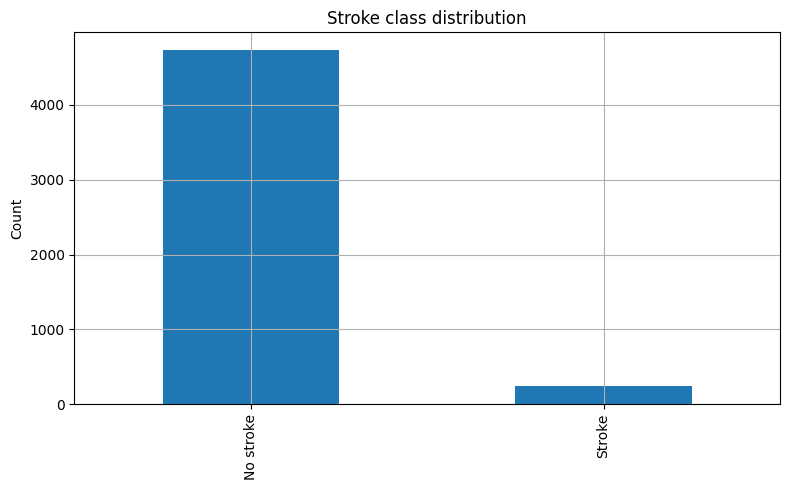

In [5]:
stroke_counts = df["stroke"].value_counts().sort_index()
stroke_rates = df["stroke"].value_counts(normalize=True).sort_index().mul(100)

display(pd.DataFrame({"count": stroke_counts, "percent": stroke_rates.round(2)}))

stroke_counts.rename(index={0: "No stroke", 1: "Stroke"}).plot(kind="bar")
plt.title("Stroke class distribution")
plt.ylabel("Count")
plt.xlabel("")
plt.tight_layout()
plt.show()


## 3. Numerical variables

In [6]:
numeric_features = ["age", "avg_glucose_level", "bmi"]

group_stats = df.groupby("stroke")[numeric_features].agg(["mean", "median", "std"])
group_stats


age                    ...        bmi                 
             mean median        std  ...       mean median       std
stroke                               ...                            
0       42.141348   43.0  22.345036  ...  28.409698  28.00  6.833637
1       67.819839   71.0  12.670565  ...  30.186694  29.45  5.658245

[2 rows x 9 columns]

/tmp/ipykernel_909/671694989.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["No stroke", "Stroke"])


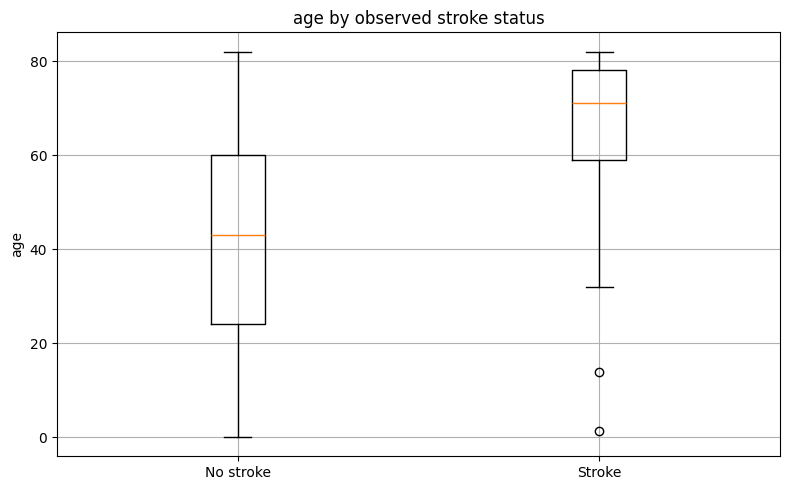

/tmp/ipykernel_909/671694989.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["No stroke", "Stroke"])


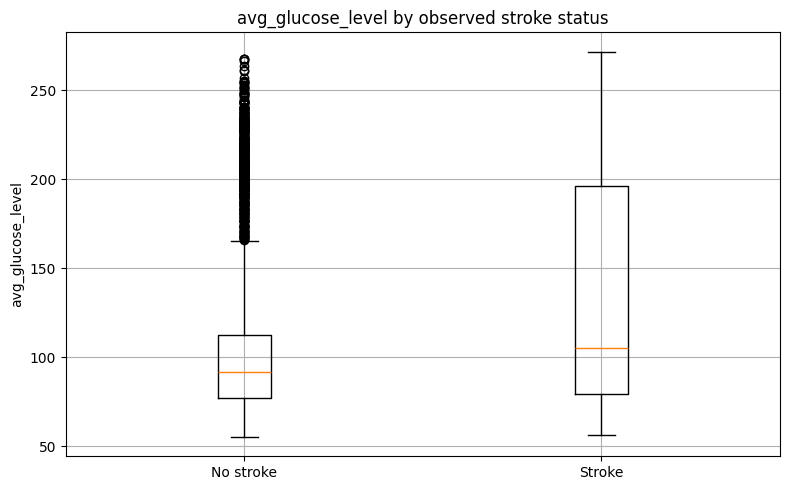

/tmp/ipykernel_909/671694989.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["No stroke", "Stroke"])


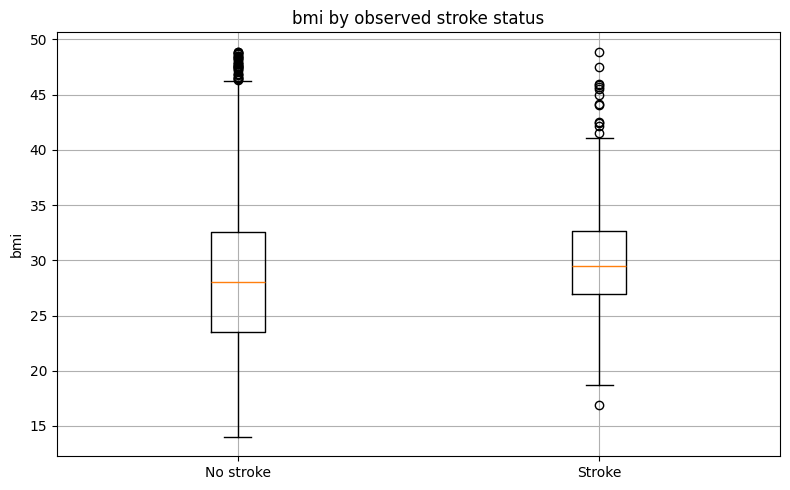

In [7]:
for feature in numeric_features:
    groups = [
        df.loc[df["stroke"] == 0, feature].dropna(),
        df.loc[df["stroke"] == 1, feature].dropna()
    ]
    plt.boxplot(groups, labels=["No stroke", "Stroke"])
    plt.title(f"{feature} by observed stroke status")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


## 4. Categorical variables

For categorical variables, raw counts can be misleading because group sizes differ. We therefore
compare the **within-category observed stroke proportion**.


In [8]:
categorical_features = [
    "gender", "hypertension", "heart_disease", "ever_married",
    "work_type", "Residence_type", "smoking_status"
]

def stroke_rate_table(data, feature):
    result = (
        data.groupby(feature, dropna=False)["stroke"]
        .agg(["count", "sum", "mean"])
        .rename(columns={"sum": "stroke_cases", "mean": "observed_stroke_rate"})
        .sort_values("observed_stroke_rate", ascending=False)
    )
    result["observed_stroke_rate"] = (result["observed_stroke_rate"] * 100).round(2)
    return result

for feature in categorical_features:
    print(f"\n### {feature}")
    display(stroke_rate_table(df, feature))



### gender


,count,stroke_cases,observed_stroke_rate
gender,,,
Male,2074,108,5.21
Female,2907,140,4.82



### hypertension


,count,stroke_cases,observed_stroke_rate
hypertension,,,
1,479,66,13.78
0,4502,182,4.04



### heart_disease


,count,stroke_cases,observed_stroke_rate
heart_disease,,,
1,275,47,17.09
0,4706,201,4.27


... (4 outputs left out)


### Residence_type


,count,stroke_cases,observed_stroke_rate
Residence_type,,,
Urban,2532,135,5.33
Rural,2449,113,4.61



### smoking_status


,count,stroke_cases,observed_stroke_rate
smoking_status,,,
formerly smoked,867,70,8.07
smokes,776,42,5.41
never smoked,1838,89,4.84
Unknown,1500,47,3.13


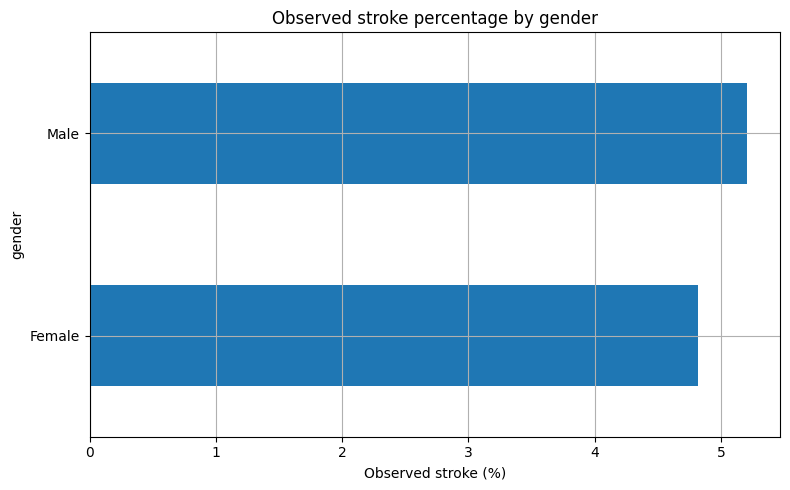

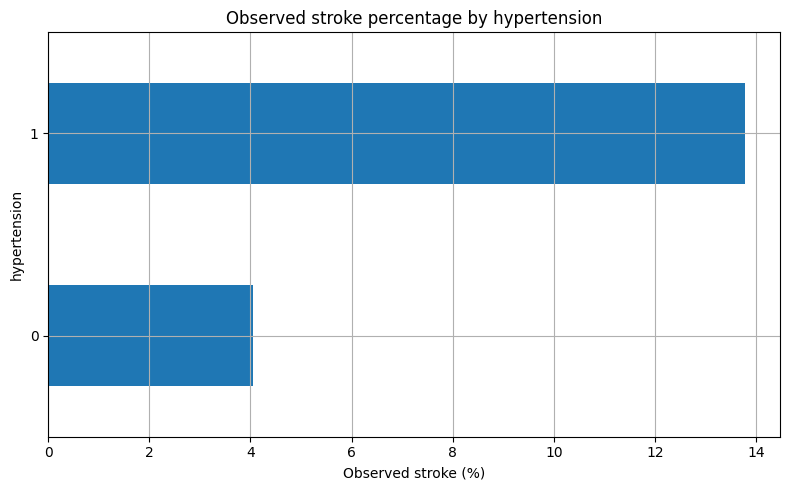

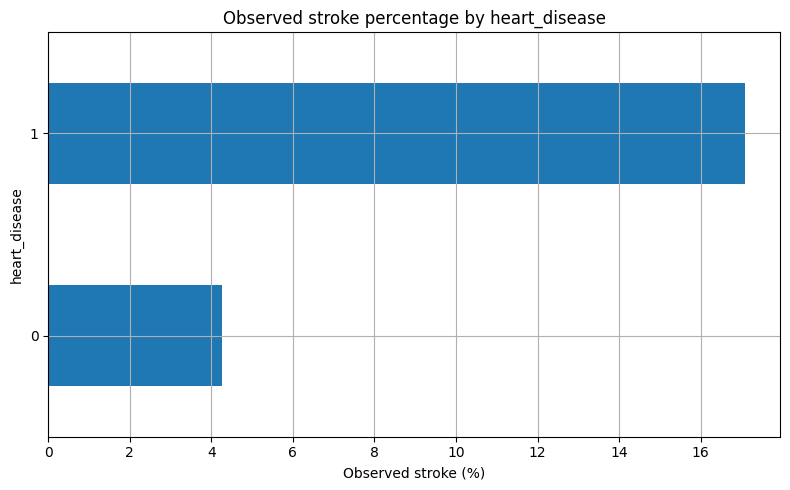

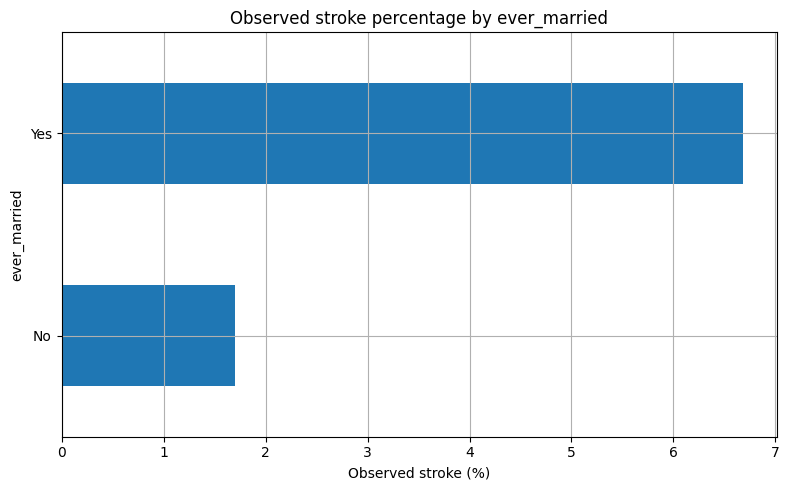

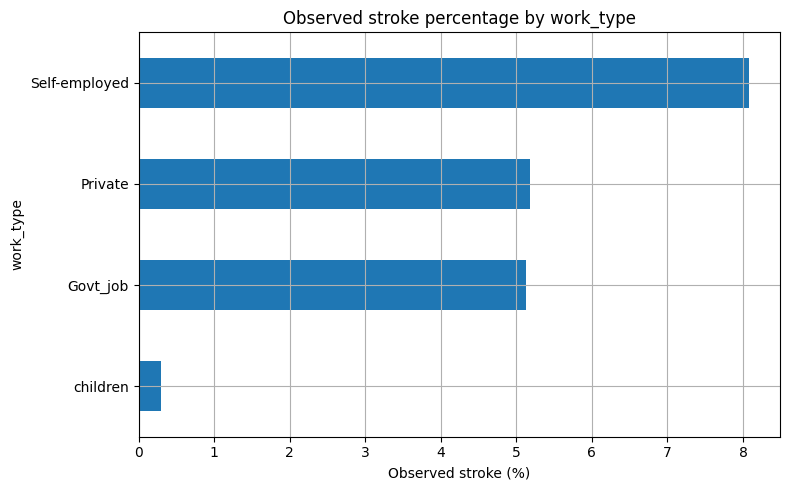

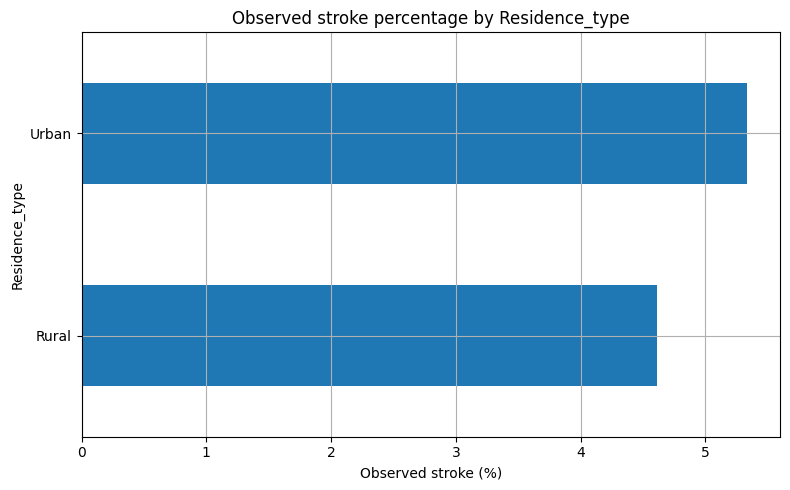

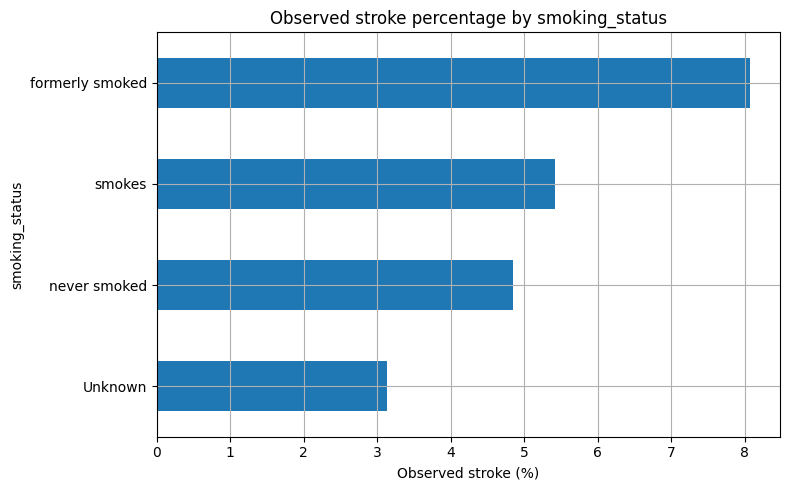

In [9]:
for feature in categorical_features:
    rates = df.groupby(feature, dropna=False)["stroke"].mean().mul(100).sort_values()
    rates.plot(kind="barh")
    plt.title(f"Observed stroke percentage by {feature}")
    plt.xlabel("Observed stroke (%)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


## 5. Correlation among numeric/binary variables

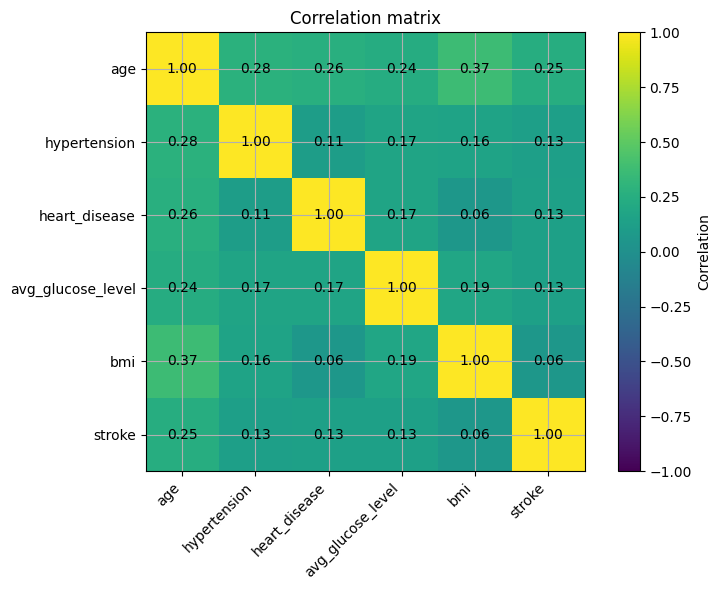

In [10]:
corr_cols = [
    "age", "hypertension", "heart_disease",
    "avg_glucose_level", "bmi", "stroke"
]
corr = df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()


## 6. Key observations and limitations

This notebook reports **associations in this dataset**, not causes.

Key patterns to inspect after running the notebook include differences in age, glucose, BMI,
hypertension, heart disease, smoking status, and other demographic variables between records with
and without an observed stroke.

### Limitations

- The target is highly imbalanced.
- The dataset is observational, so causal claims are not justified.
- The sample should not be interpreted as population prevalence.
- Important clinical variables may be absent.
- `Unknown` smoking status is a data category, not evidence of never smoking.
- This analysis is educational and is not a medical diagnostic tool.
